In [41]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import time
import src
import importlib
# allow reloading 
importlib.reload(src)

<module 'src' from 'c:\\Users\\jiyue\\OneDrive - UC San Diego\\python_projects\\corr\\src.py'>

## Introduction
We consider two strictly starionary random fields $X$ and $Y$ defined on the lattice $\mathbb{Z}^d$. The goal is to estimate the correlation between $X$ and $Y$, and compute the confidence interval and p value to capture the uncertaiy in estimation. 

## Examples

### Random field simulation 

Our method works for any dimension $d$. To illustrate this, we simulate two correlated random fields in 1D, 2D, and 3D and visualize each of them below.

The method also works when the fields are only observed on part of the grid, given by a mask. Here the 2D and 3D fields are observed inside a centered ellipse (ellipsoid in 3D) with semi-axes (0.8, 1): it spans the full grid along the second axis (the width in the plots) and 80% of it along the other axes. Grid points outside the mask are ignored.


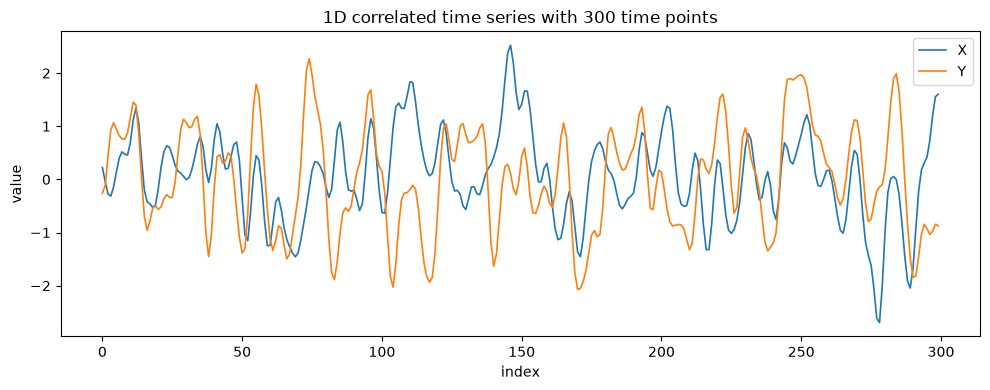

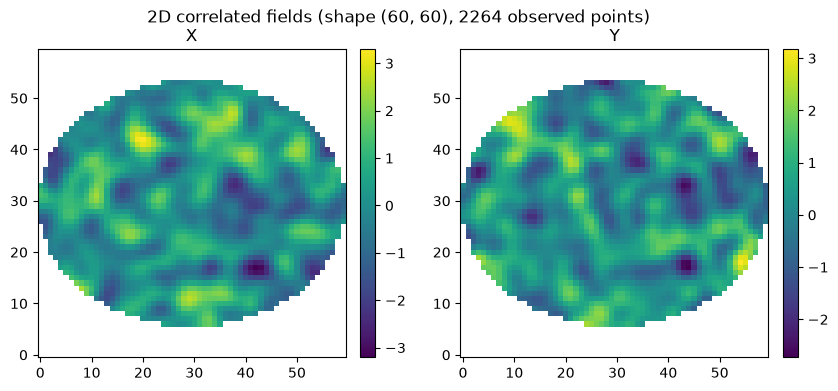

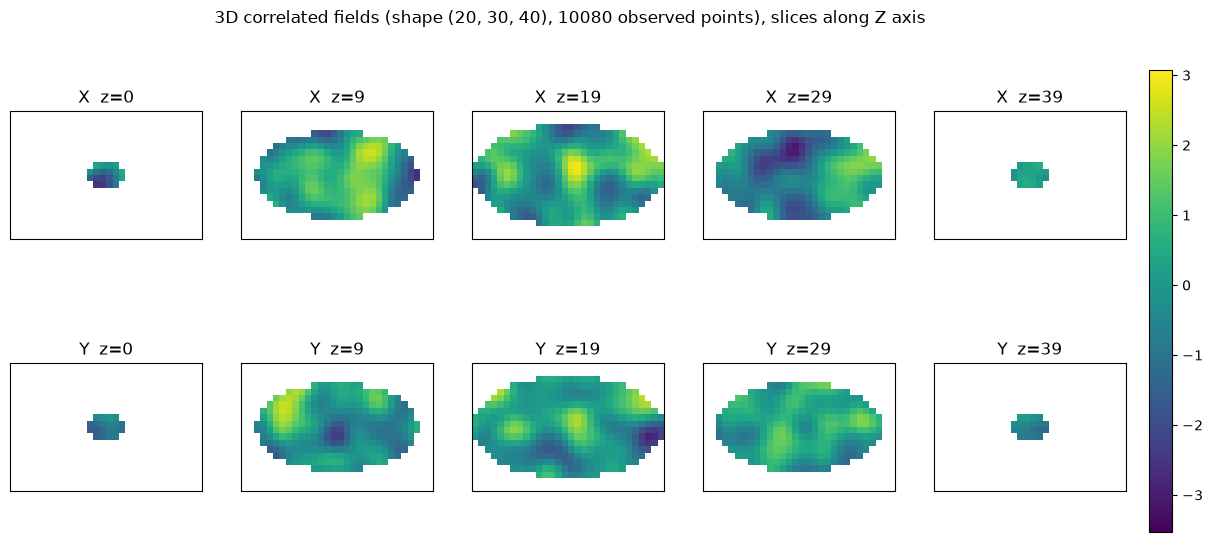

In [42]:
# specify true correlation between the two simulated random fields
rho = 0.3
# random seed for reproducibility
seed = 42

# simulate 1D time series 
X1, Y1  =  src.gen_corr_field(rho = rho,
    dim=300, seed=seed)

# simulate 2D fields
X2, Y2  =  src.gen_corr_field(rho = rho,
    dim=(60, 60), seed=seed)

# simulate 3D fields
X3, Y3  =  src.gen_corr_field(rho = rho,
    dim=(20,30,40), seed=seed)

# masks of observed grid points: a centered ellipse (2D) and ellipsoid (3D) with semi-axes
# as fractions of half the side lengths, one per array axis (rows, columns, ...); 1 on the
# second axis makes the ellipse span the full width; the 1D series is fully observed
mask2 = src.gen_mask(X2.shape, axes=(0.8, 1))
mask3 = src.gen_mask(X3.shape, axes=(0.8, 1, 1))


# visualize 1D time series
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(X1, label="X", lw=1.2)
ax.plot(Y1, label="Y", lw=1.2)
ax.set_xlabel("index")
ax.set_ylabel("value")
ax.set_title(f"1D correlated time series with {X1.shape[0]} time points")
ax.legend()
fig.tight_layout()
plt.show()

# visualize 2D fields 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, field, title in zip(axes, [X2, Y2], ["X", "Y"]):
    # points outside the mask are not observed, so they are left blank
    im = ax.imshow(np.where(mask2, field, np.nan), origin="lower", cmap="viridis")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04) 
fig.suptitle(f"2D correlated fields (shape {X2.shape}, {mask2.sum()} observed points)")
plt.show()

# visualize 3D fields as a montage of slices along the last axis
n_slices = 5
z_idx = np.linspace(0, X3.shape[2] - 1, n_slices).astype(int)

# shared color scale per field for comparable slices
vmin, vmax = min(X3[mask3].min(), Y3[mask3].min()), max(X3[mask3].max(), Y3[mask3].max())

fig, axes = plt.subplots(2, n_slices, figsize=(3 * n_slices, 6))
for row, (field, name) in enumerate(zip([X3, Y3], ["X", "Y"])):
    for col, z in enumerate(z_idx):
        ax = axes[row, col]
        im = ax.imshow(np.where(mask3, field, np.nan)[:, :, z], origin="lower",
                       cmap="viridis", vmin=vmin, vmax=vmax)
        ax.set_title(f"{name}  z={z}")
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
fig.suptitle(f"3D correlated fields (shape {X3.shape}, {mask3.sum()} observed points), slices along Z axis ")
plt.show()




### Correlation between two random fields
Now we compute the correlation between the two random fields, along with its standard error (SE). We can choose different methods to compute the SE. Since typically we are also interested in hypothesis testing under the null of no correlation, the SE under the null is also computed. For the 2D and 3D fields we pass the mask, so only the observed points are used.

In [43]:
# compute SE, available methods: 'general' (default), 'gauss', 'indep', 'iid'
# 1D
rho_est1, se1, se_under_null1, *_ = src.corr(X1, Y1, se_method="general")
print('----1D----\ncorrelation estimate:', rho_est1, '\nSE:', se1, '\nSE under null:', se_under_null1)

# 2D
rho_est2, se2, se_under_null2, *_ = src.corr(X2, Y2, mask=mask2)
print('----2D----\ncorrelation estimate:', rho_est2, '\nSE:', se2, '\nSE under null:', se_under_null2)

# 3D
rho_est3, se3, se_under_null3, *_ = src.corr(X3, Y3, mask=mask3)
print('----3D----\ncorrelation estimate:', rho_est3, '\nSE:', se3, '\nSE under null:', se_under_null3)

----1D----
correlation estimate: 0.18756627011494406 
SE: 0.08357397377880181 
SE under null: 0.09334523368456812
----2D----
correlation estimate: 0.2869566080733455 
SE: 0.06209837852027167 
SE under null: 0.07398314113473081
----3D----
correlation estimate: 0.2670470577843554 
SE: 0.04812266140794457 
SE under null: 0.05746832052705648


We can compute the confidence intervals (CI) and p values. By default, 95% CIs are computed and Fisher transformation is used for both CI computaton and p value calculation.

In [44]:
# compute confidence intervals, by default, 95% CI with Fisher transformation 
print('1D 95% CI:', src.confidence_interval(rho_est1, se1))
print('2D 95% CI:', src.confidence_interval(rho_est2, se2))
print('3D 95% CI:', src.confidence_interval(rho_est3, se3))

1D 95% CI: (0.020035969395249896, 0.34485138301267165)
2D 95% CI: (0.16119619074531036, 0.4035469499729903)
3D 95% CI: (0.17044016243906687, 0.35856905152429547)


In [45]:
# compute p value, by default with Fisher transformation 
print('1D p value:', src.pvalue(rho_est1, se_under_null1))
print('2D p value:', src.pvalue(rho_est2, se_under_null2))
print('3D p value:', src.pvalue(rho_est3, se_under_null3))

1D p value: 0.04200639776005577
2D p value: 6.587073625130557e-05
3D p value: 1.9139840947701714e-06


## Simulations
We can perform simulations to evaluate the coverage rate and power of the various variance estimation methods. 

In [46]:
# create various simulation settings
from itertools import product

# ---- factors to vary in the simulation study ----
# true correlation between the two fields 
rho_ls = [0, 0.4, -0.9, 0.9]
# number of spatial dimensions of the field (1D, 2D, 3D)
n_dim_ls = [1, 2, 3]
# side length of the d-dimensional square grid (field has nx**n_dim points)
nx_ls = [25, 50, 75, 100, 125, 150, 175, 200]
# smoothness of the field: full width at half maximum of the Gaussian kernel
fwhm_ls = [1, 2, 3, 4]
# noise distribution before smoothing
distribution_ls = ['gaussian']

# optional pointwise transform applied to the fields (None = identity, 'square' = X**2)
# sqaure a gaussian fields gives the chisq1 field
trans_ls = [None, 'square']
# field-generation method (smoothed noise via a Gaussian filter)
gen_method_ls = ['gaussian_filter']

# length scale (only used by the 'gstools' method; unused for 'gaussian_filter')
len_scale_ls = [None]
# degrees of freedom for the noise (only used for 't'/'chisq' distributions)
noise_df_ls = [None]
# mask of observed grid points, the same in every replicate: a centered ellipse (ellipsoid)
# spanning the full grid along the second axis (width) and 80% of it along the others
mask_ls = ['ellipse']

# take the Cartesian product of all factor levels -> one row per setting combination
setting_df = pd.DataFrame(
    product(nx_ls, n_dim_ls, rho_ls, len_scale_ls, fwhm_ls, gen_method_ls,
            distribution_ls, noise_df_ls, trans_ls),
    columns=['nx', 'n_dim', 'rho', 'len_scale', 'fwhm', 'gen_method',
             'distribution', 'noise_df', 'trans']
)
# semi-axes for each dimension: (1,) in 1D, (0.8, 1) in 2D, (0.8, 1, 0.8) in 3D
mask_axes_by_dim = {1: (1,), 2: (0.8, 1), 3: (0.8, 1, 0.8)}
setting_df['mask'] = mask_ls[0]
setting_df['mask_axes'] = [mask_axes_by_dim[d] for d in setting_df['n_dim']]
print(setting_df)


      nx  n_dim  rho len_scale  fwhm       gen_method distribution noise_df  \
0     25      1  0.0      None     1  gaussian_filter     gaussian     None   
1     25      1  0.0      None     1  gaussian_filter     gaussian     None   
2     25      1  0.0      None     2  gaussian_filter     gaussian     None   
3     25      1  0.0      None     2  gaussian_filter     gaussian     None   
4     25      1  0.0      None     3  gaussian_filter     gaussian     None   
..   ...    ...  ...       ...   ...              ...          ...      ...   
763  200      3  0.9      None     2  gaussian_filter     gaussian     None   
764  200      3  0.9      None     3  gaussian_filter     gaussian     None   
765  200      3  0.9      None     3  gaussian_filter     gaussian     None   
766  200      3  0.9      None     4  gaussian_filter     gaussian     None   
767  200      3  0.9      None     4  gaussian_filter     gaussian     None   

      trans     mask      mask_axes  
0       NaN  

In [47]:

from itertools import product

# ---- factors defining each SE-estimation method to compare ----
# lag-truncation rule for the HAC kernel ('auto' picks M from the number of observed points)
M_ls = ['auto']
# scaling constant applied to the chosen truncation lag M
constant_ls = [1]

# standard-error method (paper names in brackets: SE / SE under the null):
#   'iid'     - assumes independent points (no spatial correlation)
#   'indep'   - assume X and Y are independent (RFCorr-Indep-0 under the null)
#   'general' - HAC estimator for the general case (RFCorr / RFCorr-0)
#   'gauss'   - HAC estimator for the Gaussian case (RFCorr-Gauss / RFCorr-Gauss-0)
method_ls = ['iid', 'indep', 'general', 'gauss']

# kernel used to weight lags in the sum
kernel_ls = ['bartlett']

# whether to plug in the true rho in estimation (False = use the estimated rho)
use_true_rho_ls = [False]
# bandwidth for the QS kernel (None = not used for the bartlett kernel)
b_qs_ls = [None]

# Cartesian product of all factor levels -> one row per method configuration
method_df = pd.DataFrame(
    product(use_true_rho_ls, method_ls, kernel_ls, M_ls, b_qs_ls, constant_ls),
    columns=['use_true_rho', 'method', 'kernel', 'M', 'b_qs', 'constant']
)
print(method_df)


   use_true_rho   method    kernel     M  b_qs  constant
0         False      iid  bartlett  auto  None         1
1         False    indep  bartlett  auto  None         1
2         False  general  bartlett  auto  None         1
3         False    gauss  bartlett  auto  None         1


In [48]:
# test runs for a few settings 
# return_summary = True gives summaries of coverage and power; 
# set to False if you need raw results of each simulation replicate
src.sim_multiple(setting_df.head(), method_df, m_sim=50, return_summary = True)

----performing simulation, current setting number: 1, remaining settings: 4----
----performing simulation, current setting number: 2, remaining settings: 3----
----performing simulation, current setting number: 3, remaining settings: 2----
----performing simulation, current setting number: 4, remaining settings: 1----
----performing simulation, current setting number: 5, remaining settings: 0----


,setting_id,method_id,M0,bias_mean,est_sd,se_mean,n_se_na,cover_rate,cover_rate_raw,power,...,trans,mask,mask_axes,n_obs,use_true_rho,method,kernel,M,b_qs,constant
0,0,0,NaN,0.029824,0.211498,0.191055,0,0.92,0.90,0.08,...,NaN,ellipse,"(1,)",25,False,iid,bartlett,auto,None,1
1,0,1,3.0,0.029824,0.211498,0.190967,0,0.92,0.90,0.08,...,NaN,ellipse,"(1,)",25,False,indep,bartlett,auto,None,1
2,0,2,3.0,0.029824,0.211498,0.172258,0,0.86,0.84,0.06,...,NaN,ellipse,"(1,)",25,False,general,bartlett,auto,None,1
3,0,3,3.0,0.029824,0.211498,0.188486,0,0.90,0.90,0.06,...,NaN,ellipse,"(1,)",25,False,gauss,bartlett,auto,None,1
4,1,0,NaN,0.006020,0.209557,0.191386,0,0.90,0.90,0.10,...,square,ellipse,"(1,)",25,False,iid,bartlett,auto,None,1
5,1,1,3.0,0.006020,0.209557,0.191223,0,0.90,0.90,0.10,...,square,ellipse,"(1,)",25,False,indep,bartlett,auto,None,1
6,1,2,3.0,0.006020,0.209557,0.142221,0,0.78,0.76,0.00,...,square,ellipse,"(1,)",25,False,general,bartlett,auto,None,1
7,1,3,3.0,0.006020,0.209557,0.189546,0,0.90,0.90,0.10,...,square,ellipse,"(1,)",25,False,gauss,bartlett,auto,None,1
8,2,0,NaN,-0.096074,0.285193,0.182212,0,0.72,0.70,0.28,...,NaN,ellipse,"(1,)",25,False,iid,bartlett,auto,None,1
9,2,1,3.0,-0.096074,0.285193,0.231753,0,0.90,0.82,0.10,...,NaN,ellipse,"(1,)",25,False,indep,bartlett,auto,None,1
